# **WIH2001 DATA ANALYTICS**

**Name:** Nur Fatnin Jazmina binti Jimmy

**Matric Number:** 24004490



#<font color = "#2e86c1">**Section 1: Dataset**</font>

Dataset [Movie vs. Emotional Attachment Survey](https://www.kaggle.com/datasets/andrewdevila/movie-vs-emotional-attachment-survey?select=Movie+vs+Emotional+Attachment+Survey+2024-2026.csv)

Source: Kaggle

The dataset chosen is from a survey from more than 5000 audience responses regarding their emotional connections to various films.

In [342]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/movie_emotional_attachment1.csv', encoding = 'latin1')


#<font color = "#2e86c1"> **Section 2: Business Understanding**</font>


## <font color = "#fad000"> **Topic: Analysis on WHY Some Movies Never Leave Our Hearts**</font>

---



### <font color = "#e05194"> **2.1 Problem Statement**</font>

While thousands of movies are produced annually, only a fraction creates a lifelong emotional bond with viewers. Thus, movie producers may be in a risk of massive financial losses on content that has no "rewatchability". By performing this analysis, we can investigate the key drivers behind why we can remember certain films forever.

### <font color = "#e05194"> **2.2 Objectives**</font>

* To determine which **factor has the highest correlation** with a movie having a "special place in memory".
* To analyze **impact of character attachment vs storytelling power** on overall audience satisfaction
* To determine if **demographical factors** like age or gender, play a role in emotional resonance

### <font color = "#e05194"> **2.3 Potiental Impact**</font>

**1) Streaming Platforms** (e.g. Netflix, Disney)
* Can improve recommendation engines by focusing on "emotional resonance" rather than just genre

**2) Screenwriters and producers**
* Higher ***Return on Investment*** (**ROI**) by creating "Evergreen" content that generates revenue through streaming and merchandise for decades.
* Help them focus their resources on the specific emotional triggers that ensure long-term audience retention and recommendation rates.



# <font color = "#2e86c1"> **Section 3: Data Understanding**</font>

## <font color = "#e05194"> **3.1 Dataset Description**</font>

###a) **Number of Records**: *5002*

###b) **Number of Attributes**: *18*

###c) **Attribute Types**:
   * <mark style="background-color: #fad000">**Categorical (Object)**:</mark>  Age, Gender, Watched emotional movie, Movie Title, Frequency, Recency.

   * <mark style="background-color: #fad000">**Numerical (Integer/Float)**:</mark> 10 Likert-scale questions(1-5) measuring Storytelling Quality & Audience Attachment and Calculated Average Scores (Storytelling Score, Attachment Score)



In [343]:
print(f"Total Records: {df.shape[0]}")
print(f"Total Attributes: {df.shape[1]}")
df.head()

Total Records: 5002
Total Attributes: 18


,Age,Gender,Watched emotional movie in last 12 months,Movie/Book that affected you most recently,How many times watched,When watched most recently,The storytelling in this movie was emotionally powerful.,The story made me feel strong emotions.,The emotional moments felt genuine and realistic.,The characters' emotional experiences were clearly expressed.,The story focused strongly on characters' feelings and relationships.,I feel attached to the characters in this movie.,I still think about this movie or its characters after watching it.,I would like to watch this movie again in the future.,I would recommend this movie to others.,This movie has a special place in my memory compared to other movies.,Emotional Storytelling Score,Audience Attachment Score
0,24 or above,Male,Yes,An Affair to Remember,More than 3 times,1?6 months ago,4,4.0,3,4,3,4.0,3,3.0,2,3,3.6,3.0
1,18?20,Female,Yes,Everything Everywhere All at Once,1 time,1?6 months ago,4,4.0,2,2,4,NaN,3,5.0,4,4,NaN,3.8
2,24 or above,Female,Yes,Good Will Hunting,1 time,1?6 months ago,4,3.0,3,2,2,4.0,3,4.0,4,3,2.8,3.6
3,24 or above,Female,Yes,Atonement,1 time,Within last 1 month,4,3.0,4,3,4,2.0,5,5.0,3,4,3.6,3.8
4,24 or above,Female,Yes,Wild Strawberries,1 time,1?6 months ago,4,3.0,3,5,4,2.0,5,3.0,3,2,3.8,3.0


In [344]:
print("\n--- Attribute Data Types---")
print(df.dtypes)
#print(df.info())


--- Attribute Data Types---
Age                                                                       object
Gender                                                                    object
Watched emotional movie in last 12 months                                 object
Movie/Book that affected you most recently                                object
How many times watched                                                    object
When watched most recently                                                object
The storytelling in this movie was emotionally powerful.                   int64
The story made me feel strong emotions.                                  float64
The emotional moments felt genuine and realistic.                          int64
The characters' emotional experiences were clearly expressed.              int64
The story focused strongly on characters' feelings and relationships.      int64
I feel attached to the characters in this movie.                         float64

##<font color = "#e05194"> **3.2 Summary Statistics**</font>

In [345]:
print("\n---Numerical Data---")
numeric_cols = df.select_dtypes(include = ['int64', 'float64'])
stats = numeric_cols.agg(['mean', 'median', 'std']).transpose()
display(stats)


---Numerical Data---


,mean,median,std
The storytelling in this movie was emotionally powerful.,3.556977,4.0,1.021099
The story made me feel strong emotions.,3.540492,4.0,1.057171
The emotional moments felt genuine and realistic.,3.538385,4.0,1.074986
The characters' emotional experiences were clearly expressed.,3.547981,4.0,1.060741
The story focused strongly on characters' feelings and relationships.,3.554378,4.0,1.106751
I feel attached to the characters in this movie.,3.275145,3.0,1.079944
I still think about this movie or its characters after watching it.,3.308876,3.0,1.065894
I would like to watch this movie again in the future.,3.294341,3.0,1.117026
I would recommend this movie to others.,3.297481,3.0,1.077236
This movie has a special place in my memory compared to other movies.,3.312075,3.0,1.077468


In [346]:
print("\n---Categorical Data---")
df.describe(include = 'object')


---Categorical Data---


,Age,Gender,Watched emotional movie in last 12 months,Movie/Book that affected you most recently,How many times watched,When watched most recently
count,5001,5002,5002,5001,5002,5002
unique,5,3,2,214,3,3
top,21?23,Female,Yes,Forrest Gump,1 time,1?6 months ago
freq,1736,2499,5001,79,2000,1978


We noticed that the number of count is not tally, meaning there's missing value in some rows, we prove it by running this code:

##<font color = "#e05194"> **3.3 Initial Observations**</font>

### **During initial exploration, the following *patterns* and *anomalies* were detected:**

1) <font color = '#fad000'>**Noise in categorical data:**</font> The <code>Age</code> & <code>When watched most recently</code> columns contains characters like <mark style="background-color: #fad000">"21?23" and "1?6months"</mark> instead of <font color = '#74c365'>**"21 - 23" and "1-6 months**.</font>

2) <font color = '#fad000'>**Presence of Anomaly:**</font> One respondent is listed under <mark style="background-color: #fad000">"Under 12"</mark> in the Age group. In a dataset of 5001 other young adults, this is a <font color = '#db4035'>***statistical anomaly***</font> that may not represent the target audience for complex emotional cinema.

3) <font color = '#fad000'>**Missing Values:** </font>Some rows contain null values <font color = '#db4035'>**NaN**</font> as seen in DATA FRAMES, in critical emotional score columns can lead to calculation errors.


### 1) Noise in Categorical Data

In [347]:
# 1. Detect noise using Regex (Searching for '?')
age_noise = df['Age'].str.contains(r'\?', na=False)
watch_noise = df['When watched most recently'].str.contains(r'\?', na=False)

# 2. Display the exact noisy patterns found
print("--- NOISE DETECTION REPORT ---")
print(f"Noisy Age patterns: {df[age_noise]['Age'].unique()}")
print(f"Noisy 'When watched' patterns: {df[watch_noise]['When watched most recently'].unique()}")

# 3. Quantify the impact for the presentation
print("\n--- IMPACT ANALYSIS ---")
print(f"Rows affected in 'Age': {age_noise.sum()} ({age_noise.mean()*100:.1f}%)")
print(f"Rows affected in 'Watch Recency': {watch_noise.sum()} ({watch_noise.mean()*100:.1f}%)")

--- NOISE DETECTION REPORT ---
Noisy Age patterns: ['18?20' '21?23']
Noisy 'When watched' patterns: ['1?6 months ago']

--- IMPACT ANALYSIS ---
Rows affected in 'Age': 2872 (57.4%)
Rows affected in 'Watch Recency': 1978 (39.5%)


### 2) Presence of Anomalies

Significant Outlier/Anomalies detected: 1 record for 'Under 12'



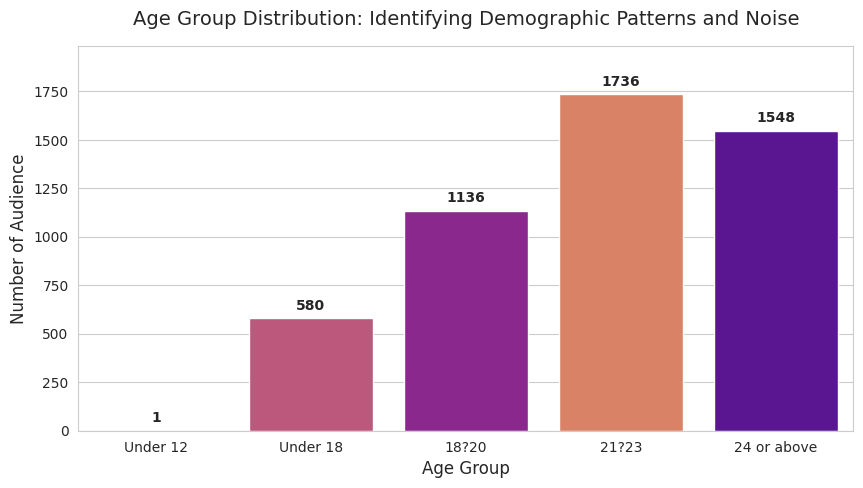

In [348]:
print(f"Significant Outlier/Anomalies detected: {len(df[df['Age'] == 'Under 12'])} record for 'Under 12'\n")

# Set the plot style for a professional look
sns.set_style("whitegrid")

plt.figure(figsize=(10, 5))

# Use the manually defined age_order
age_order = ['Under 12', 'Under 18', '18?20', '21?23', '24 or above']

# Create the countplot
ax = sns.countplot(x='Age', data=df, palette='plasma', order=age_order, hue='Age', legend= False)

# Add title and labels
plt.title('Age Group Distribution: Identifying Demographic Patterns and Noise', fontsize=14, pad=15)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Number of Audience', fontsize=12)

# Data labels
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center', va = 'center',
                xytext = (0, 9),
                textcoords = 'offset points',
                fontsize=10, fontweight='bold')

plt.ylim(0, df['Age'].value_counts().max() + 250)
plt.show()

### 3) Missing Values

In [349]:
# Searching for columns with missing values
print(f"Total NaN values detected: {df.isnull().sum().sum()}")

# 1. Show total number of columns that contain at least one missing value
cols_with_missing = df.isnull().any().sum()
print(f"Total columns with missing values: {cols_with_missing}")

# 2. List the specific columns with their missing values
print("\nColumns with missing values:\n")
print(df.isnull().sum()[df.isnull().sum()>0])

# 3. Search for and display the rows that contain missing values (NaN)
# We use .any(axis=1) to find rows where at least one column is null
rows_with_nan = df[df.isnull().any(axis=1)]

print(f"\nTotal rows with missing values: {len(rows_with_nan)}")
print("\n---Displaying rows with missing values---")

styled_rows = rows_with_nan.style.highlight_null(color='red')
display(styled_rows)

Total NaN values detected: 7
Total columns with missing values: 7

Columns with missing values:

Age                                                      1
Movie/Book that affected you most recently               1
The story made me feel strong emotions.                  1
I feel attached to the characters in this movie.         1
I would like to watch this movie again in the future.    1
Emotional Storytelling Score                             1
Audience Attachment Score                                1
dtype: int64

Total rows with missing values: 5

---Displaying rows with missing values---


,Age,Gender,Watched emotional movie in last 12 months,Movie/Book that affected you most recently,How many times watched,When watched most recently,The storytelling in this movie was emotionally powerful.,The story made me feel strong emotions.,The emotional moments felt genuine and realistic.,The characters' emotional experiences were clearly expressed.,The story focused strongly on characters' feelings and relationships.,I feel attached to the characters in this movie.,I still think about this movie or its characters after watching it.,I would like to watch this movie again in the future.,I would recommend this movie to others.,This movie has a special place in my memory compared to other movies.,Emotional Storytelling Score,Audience Attachment Score
1,18?20,Female,Yes,Everything Everywhere All at Once,1 time,1?6 months ago,4,4.000000,2,2,4,nan,3,5.000000,4,4,nan,3.800000
13,18?20,Male,Yes,Silver Linings Playbook,1 time,More than 6 months ago,2,3.000000,3,3,3,2.000000,3,nan,3,2,0.600000,nan
4703,24 or above,Prefer not to say,Yes,nan,More than 3 times,1?6 months ago,4,4.000000,5,5,5,4.000000,4,5.000000,5,5,4.600000,4.600000
4762,21?23,Female,Yes,The Boy in the Striped Pyjamas,More than 3 times,More than 6 months ago,2,nan,1,2,1,2.000000,2,1.000000,1,2,1.400000,1.600000
4866,nan,Male,Yes,Spirited Away,More than 3 times,Within last 1 month,5,5.000000,5,3,5,5.000000,5,4.000000,5,5,4.600000,4.800000


# <font color = "#2e86c1"> **Section 4: Data Preprocessing**</font>

## <font color="#e05194">**4.1 Handling Missing Values (NaN)**</font>

* **Method**: *Removal*  
(deleting the rows with missing data)

* **Justification**:

The dataset contains 5,002 records. After checking for missing values, only a 0.2% of rows were found to be incomplete. I have chosen to remove these rows rather than using imputation. This ensures that our analysis of 'emotional attachment' is based entirely on authentic, completed user surveys, avoiding the potential bias of 'guessed' values.


---MISSING VALUES PER COLUMNS---



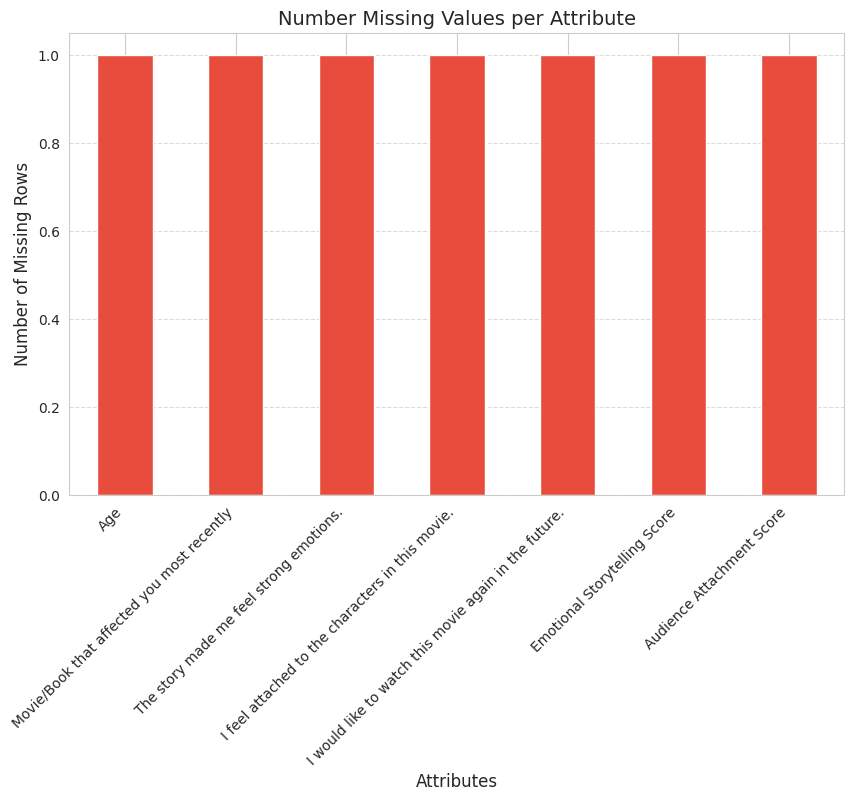


Rows before cleaning: 5002
Rows after removing NaN: 4997
Total rows removed: 5


In [350]:
print(f"---MISSING VALUES PER COLUMNS---\n")

# Calculate missing values
missing_data = df.isnull().sum()
missing_data = missing_data[missing_data > 0] # Only show columns with issues

# Plotting
plt.figure(figsize=(10, 6))
missing_data.plot(kind='bar', color='#e74c3c')

plt.title('Number Missing Values per Attribute', fontsize=14)
plt.xlabel('Attributes', fontsize=12)
plt.ylabel('Number of Missing Rows', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Define df_clean by dropping rows with any missing values
df_clean = df.dropna().copy()


print(f"\nRows before cleaning: {len(df)}")
print(f"Rows after removing NaN: {len(df_clean)}")
print(f"Total rows removed: {len(df) - len(df_clean)}")

##<font color="#e05194">**4.2 Handling Noise & Outliers**</font>


### 1) Fixing '?' in Age Column

In the raw data, some <code>Age</code> and <code>When watched recently columns</code> appear as  <mark style="background-color: #fad000">'18?20' and '1?6 months'</mark> respectively. We change this to  <mark style="background-color: #fad000">'18-20' and '1-6 months</mark> for easier readibility.

**Justification:**

The <code>Age</code> and <code>When watched recently columns</code> attribute contained encoding noise where a question mark **'?'** appeared instead of a range separator **'-'**. I applied a string replacement
transformation to standardize the categories into a readable <code>'XX–XX' and 'X- X months</code> format,
ensuring professional presentation in final visualizations."

In [351]:
# 1. CLEANING: Replacing '?' with '–' in both columns
# We use r'\?' to escape the special character in regex
df_clean['Age'] = df_clean['Age'].str.replace(r'\?', '–', regex=True)
df_clean['When watched most recently'] = df_clean['When watched most recently'].str.replace(r'\?', '–', regex=True)

# 2. VERIFICATION: Checking that '?' no longer exists
age_noise_remaining = df_clean['Age'].str.contains(r'\?', na=False).sum()
watch_noise_remaining = df_clean['When watched most recently'].str.contains(r'\?', na=False).sum()

print("--- Verification Results ---")
print(f"Remaining noise in Age: {age_noise_remaining}")
print(f"Remaining noise in Watch Recency: {watch_noise_remaining}")

# 3. SHOWING CLEAN LABELS
print("\n--- Cleaned Categories ---")
print(f"Standardized Ages: {df_clean['Age'].unique()}")
print(f"Standardized Watch Recency: {df_clean['When watched most recently'].unique()}")

--- Verification Results ---
Remaining noise in Age: 0
Remaining noise in Watch Recency: 0

--- Cleaned Categories ---
Standardized Ages: ['24 or above' 'Under 18' '18–20' '21–23' 'Under 12']
Standardized Watch Recency: ['1–6 months ago' 'Within last 1 month' 'More than 6 months ago']


### 2) Identify & treat outliers

Justification:

An anomaly was identified where a single respondent fell into the **'Under 12'** age category. Given that the analysis focuses on deep emotional storytelling and character attachment where often times require maturity.

This single record is called **significant outlier**. Thus, now the demographic analysis remains focused on the primary audience (18+).

In [352]:
#Searching for specific row that contained the outlier
outlier_row = df_clean[df_clean['Age']== 'Under 12']

print(f"Number of 'Under 12' respondents: {len(outlier_row)}")
display(outlier_row)

Number of 'Under 12' respondents: 1


,Age,Gender,Watched emotional movie in last 12 months,Movie/Book that affected you most recently,How many times watched,When watched most recently,The storytelling in this movie was emotionally powerful.,The story made me feel strong emotions.,The emotional moments felt genuine and realistic.,The characters' emotional experiences were clearly expressed.,The story focused strongly on characters' feelings and relationships.,I feel attached to the characters in this movie.,I still think about this movie or its characters after watching it.,I would like to watch this movie again in the future.,I would recommend this movie to others.,This movie has a special place in my memory compared to other movies.,Emotional Storytelling Score,Audience Attachment Score
5000,Under 12,Female,No,27 Dresses,More than 3 times,Within last 1 month,3,4.0,5,5,5,4.0,5,4.0,5,6,4.6,4.0


In [353]:
#remove outlier from dataset

df_clean = df_clean[df_clean['Age'] != 'Under 12']


##<font color="#e05194">**4.3 Data Transformation**</font>


###1) Encoding Age & Gender Categories to Numerical Ranks

Charts will now be perfectly sorted 1-5 without any string code.

**Justfication:**

Numerical values to calculate correlation coeffecient

**Advantages:**

a) No manually typing age_order lists in every single plot


In [354]:
# 1. Manual Mapping for Age (Ensures logical order: 1 < 2 < 3 < 4)
age_map = {
    'Under 18': 1,
    '18–20': 2,
    '21–23': 3,
    '24 or above': 4
}
df_clean['age'] = df_clean['Age'].map(age_map)

# 2. Manual Mapping for Gender (More precise than LabelEncoder)
gender_map = {
    'Male': 0,
    'Female': 1,
    'Prefer not to say': 2
}
df_clean['gender'] = df_clean['Gender'].map(gender_map)

# 3. Verification
print("--- Corrected Age Ranks (Logical Order) ---")
print(df_clean[['Age', 'age']].drop_duplicates().sort_values('age'))

print("\n--- Corrected Gender Ranks ---")
print(df_clean[['Gender', 'gender']].drop_duplicates())

--- Corrected Age Ranks (Logical Order) ---
           Age  age
7     Under 18    1
8        18–20    2
9        21–23    3
0  24 or above    4

--- Corrected Gender Ranks ---
              Gender  gender
0               Male       0
2             Female       1
7  Prefer not to say       2


##<font color="#e05194">**4.4 Data Cleaning**</font>


### 1) Renaming columns

Long survey questions are being renamed for better readibility in graph and charts

Justification: Short names prevent overlapped axis labels in visualization and easy to read.



In [355]:
rename_dict = {
    'The storytelling in this movie was emotionally powerful.': 'story_power',
    'The characters\' emotional experiences were clearly expressed.': 'char_expression',
    'I feel attached to the characters in this movie.': 'char_attachment',
    'I still think about this movie or its characters after watching it.': 'lingering_thought',
    'I would like to watch this movie again in the future.': 'rewatch_intent',
    'This movie has a special place in my memory compared to other movies.': 'memory_impact',
    'Emotional Storytelling Score': 'emotional_storytelling_avg_score',
    'Audience Attachment Score': 'audience_attachment_avg_score'}

df_clean = df_clean.rename(columns=rename_dict)


### 2) Handling duplicate records

Removing duplicates ensures that a single respondent's data does not carry double weight in our statistical calculations, maintaining the validity of our correlation findings.

In [356]:
# 1. search for exact duplicates

exact_duplicates = df.duplicated().sum()
print(f"Number of exact duplicates rows found: {exact_duplicates}")

# 2. displaying the duplicate rows (if any)
if exact_duplicates > 0:
    display(df_clean[df_clean.duplicated()])

# 3. removing duplicates

df_clean = df_clean.drop_duplicates()


Number of exact duplicates rows found: 1


,Age,Gender,Watched emotional movie in last 12 months,Movie/Book that affected you most recently,How many times watched,When watched most recently,story_power,The story made me feel strong emotions.,The emotional moments felt genuine and realistic.,char_expression,The story focused strongly on characters' feelings and relationships.,char_attachment,lingering_thought,rewatch_intent,I would recommend this movie to others.,memory_impact,emotional_storytelling_avg_score,audience_attachment_avg_score,age,gender
5001,Under 18,Female,Yes,Matilda,2?3 times,1–6 months ago,3,3.0,4,3,2,4.0,4,3.0,4,4,3.0,3.8,1,1


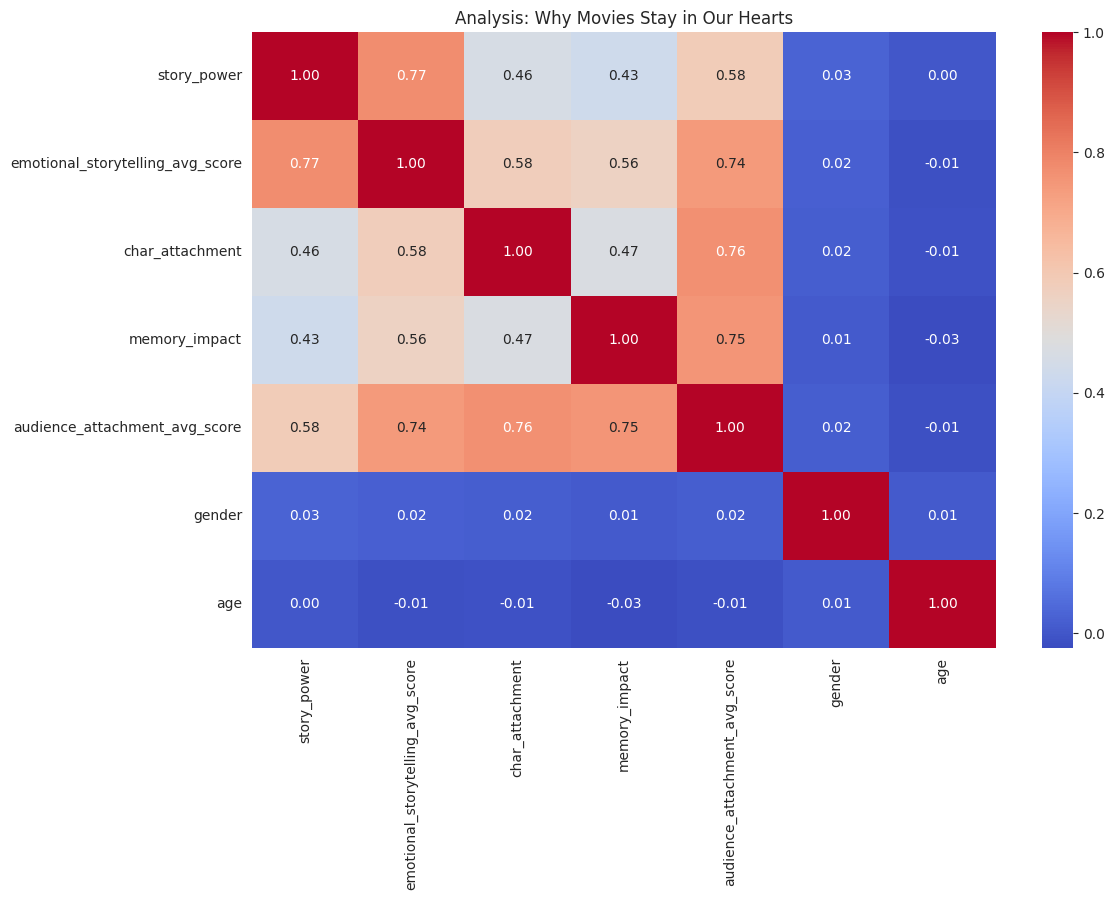

In [357]:
# The Correlation Heatmap
plt.figure(figsize=(12, 8))
cols = ['story_power', 'emotional_storytelling_avg_score','char_attachment', 'memory_impact', 'audience_attachment_avg_score', 'gender', 'age']
sns.heatmap(df_clean[cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Analysis: Why Movies Stay in Our Hearts')
plt.show()